# 5. The pipeline: gene selection and the graph model under nested cross-validation

Question: does a graph model on genes selected inside each training part predict overall survival better than the clinical covariates alone, and what is the final model?

What enters: the TCGA-BRCA cohort table of notebook 1 and the STRING edge list of notebook 4.

What leaves: one file per outer fold, the final frozen model and the summary tables in `results/05_pipeline/`.

Result: the line under the imports is rendered from the saved summary.

How to run: the nbconvert command of the other notebooks; by default the notebook reads the saved results in seconds, and the compute switch in the settings starts the full run of several hours.

In [1]:
import hashlib
import json
import subprocess
import sys
import time
import warnings
from importlib.metadata import version
from pathlib import Path

warnings.simplefilter("ignore", FutureWarning)  # torch's import-time notice about torch.jit
warnings.filterwarnings("ignore", module="tqdm")  # tqdm asks for a widget the notebook lacks

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from scipy import stats
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sksurv.linear_model import CoxnetSurvivalAnalysis, CoxPHSurvivalAnalysis
from sksurv.metrics import concordance_index_censored, concordance_index_ipcw
from sksurv.util import Surv
from torch_geometric.data import Batch, Data
from torch_geometric.nn import SAGEConv, global_mean_pool
from torchsurv.loss.cox import neg_partial_log_likelihood

In [2]:
summary_file = Path("../results/05_pipeline/summary.csv")
if summary_file.exists():
    saved = pd.read_csv(summary_file, index_col=0)["value"]
    display(Markdown(f"Result: over {saved['outer folds done']} of 5 outer folds the graph model "
                     f"has a mean Harrell's C of {float(saved['graph model mean C']):.3f}, the "
                     f"clinical-only Cox {float(saved['clinical-only Cox mean C']):.3f}; the "
                     f"paired difference is {float(saved['graph minus clinical mean']):.3f} with "
                     "interval "
                     f"{float(saved['graph minus clinical lower']):.3f} to "
                     f"{float(saved['graph minus clinical upper']):.3f}."))
else:
    display(Markdown("Result: not yet run."))

Result: over 5 of 5 outer folds the graph model has a mean Harrell's C of 0.717, the clinical-only Cox 0.730; the paired difference is -0.013 with interval -0.098 to 0.072.

## Settings

Every grid, seed and cut-off of the procedure is set here once. The compute switch is set to no, so the notebook reads the saved results; setting it to yes computes the outer folds whose file is missing, then the final model.

In [3]:
COMPUTE = False             # no: read the saved results; yes: compute the missing outer folds
SCORE_METABRIC = False      # no until the supervisors confirm the procedure; the model is frozen
RUN_NO_GRAPH = True         # the same model with the edges removed, after the mandatory results
RESULTS = Path("../results/05_pipeline")
DATA_FILE = Path("../data/processed/tcga.parquet")
EDGE_FILE = Path("../results/04_gene_graph/edges_700.csv.gz")
OUTER_FOLDS = 5             # the outer loop scores the procedure
INNER_FOLDS = 5             # the inner loop chooses every setting
FOLD_SEED = 0               # fixed fold assignment
TORCH_SEED = 0              # fixed weight initialisation per training
EXPRESSED_AT = 1.0          # a gene counts as expressed at log2(TPM + 1) >= 1
EXPRESSED_IN = 0.2          # in at least 20% of the training patients
L1_RATIOS = [0.5, 0.75, 1.0]  # elastic net between half L1 and the LASSO
PENALTIES = 25              # penalties on the library's path
SMALLEST_PENALTY = 0.05     # the path ends at 5% of the largest penalty
LIST_MIN, LIST_MAX = 10, 1000  # an eligible gene list: enough for a graph, small enough to train
HIDDEN_SIZES = [64, 128]    # width of the graph layers
DROPOUTS = [0.2, 0.5]       # dropout after each layer
LEARNING_RATE = 0.001       # Adam
WEIGHT_DECAY = 0.0001       # L2 penalty of Adam
EPOCHS = 40                 # fixed; the last epoch is scored, no epoch is picked on validation data
CLINICAL_RIDGE = 0.001      # a small ridge keeps the clinical Cox finite when a level is rare
HORIZON_DAYS = 5 * 365.25   # Uno's C is computed up to five years

## Data

The cohort table is the one notebook 1 wrote, checked by its hash, with the outcome, five clinical covariates and one column per pool gene. The edge list is the STRING graph of notebook 4.

In [4]:
table = pd.read_parquet(DATA_FILE)
cohort = json.loads(Path("../results/01_data/cohort.json").read_text())["tcga"]
data_hash = hashlib.sha256(DATA_FILE.read_bytes()).hexdigest()
assert data_hash == cohort["file sha256"], "the cohort table is not the one notebook 1 wrote"
OUTCOME = ["os_days", "os_event"]
CLINICAL = ["age", "stage", "er", "pr", "her2"]
CATEGORIES = CLINICAL[1:]
GENES = [column for column in table.columns if column.startswith("ENSG")]
assert len(GENES) + len(CLINICAL) + len(OUTCOME) == table.shape[1], "an unexpected column"
edges = pd.read_csv(EDGE_FILE)
edge_hash = hashlib.sha256(EDGE_FILE.read_bytes()).hexdigest()
display(Markdown(f"{len(table)} patients, {int(table['os_event'].sum())} deaths, {len(GENES)} pool "
                 f"genes, {len(edges)} STRING edges at score 700 or more."))

1064 patients, 150 deaths, 19211 pool genes, 257653 STRING edges at score 700 or more.

## Which patients each step sees

The outer loop holds one fifth of the patients out and scores the procedure on it; inside each training part the inner loop holds one fifth out twice, once to choose the selector's settings and once to choose the graph model's settings. The figure counts patients and deaths in each part for the first outer fold.

In [5]:
def folds(part, count):
    """The (training, held-out) row pairs of one part, stratified by the event flag."""
    splitter = StratifiedKFold(count, shuffle=True, random_state=FOLD_SEED)
    return list(splitter.split(part.index, part["os_event"]))


def outcome_of(part):
    """The outcome of one part in the library's structured form."""
    return Surv.from_arrays(part["os_event"].astype(bool), part["os_days"])


def part_label(name, part):
    """Patients and deaths of one part, for the figure."""
    return f"{name}: {len(part)} patients, {int(part['os_event'].sum())} deaths"


outer = folds(table, OUTER_FOLDS)
first_training = table.iloc[outer[0][0]]
bars = [("outer fold 1 training part", "outer fold 1 test part", table, outer[0])]
for number, inner_rows in enumerate(folds(first_training, INNER_FOLDS), start=1):
    bars.append((f"inner fold {number} fit part", f"inner fold {number} validation part",
                 first_training, inner_rows))

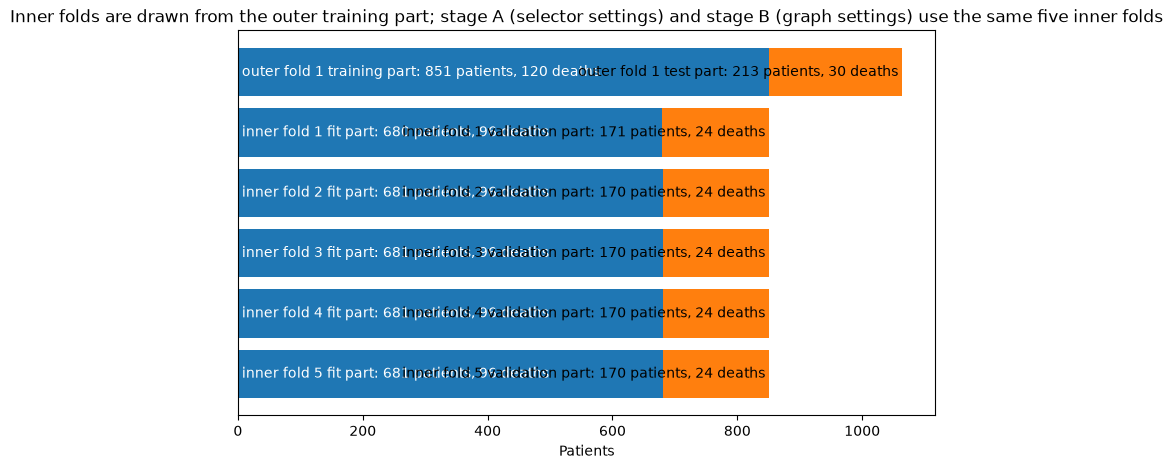

In [6]:
figure, axis = plt.subplots(figsize=(9, 5))
for position, (fit_name, score_name, part, (fit_rows, score_rows)) in enumerate(bars):
    fit_part, score_part = part.iloc[fit_rows], part.iloc[score_rows]
    axis.barh(-position, len(fit_part), color="tab:blue")
    axis.barh(-position, len(score_part), left=len(fit_part), color="tab:orange")
    axis.text(0, -position, " " + part_label(fit_name, fit_part), va="center", color="white")
    axis.text(len(part), -position, part_label(score_name, score_part) + " ", va="center",
              ha="right")
axis.set_yticks([])
axis.set_xlabel("Patients")
axis.set_title("Inner folds are drawn from the outer training part; stage A (selector settings) "
               "and stage B (graph settings) use the same five inner folds")
plt.show()

## Preprocessing inside the training part

The expression filter and the z-scoring of genes and age are fitted on the training part of each fold, inner or outer, and applied to its held-out part. The categorical covariates are one-hot encoded with their unknown level.

In [7]:
def scaled_expression(train, other):
    """Keep genes expressed in enough training patients and z-score them on the training part."""
    expressed = (train[GENES] >= EXPRESSED_AT).mean() >= EXPRESSED_IN
    kept = list(expressed.index[expressed])
    scaler = StandardScaler().fit(train[kept])
    train_scaled = pd.DataFrame(scaler.transform(train[kept]), index=train.index, columns=kept)
    other_scaled = pd.DataFrame(scaler.transform(other[kept]), index=other.index, columns=kept)
    return train_scaled, other_scaled


def clinical_vectors(train, other, drop=None):
    """Age z-scored and stage, ER, PR and HER2 one-hot, fitted on the training part."""
    encoder = OneHotEncoder(drop=drop, sparse_output=False, handle_unknown="ignore")
    encoder.fit(train[CATEGORIES])
    scaler = StandardScaler().fit(train[["age"]])
    vectors = []
    for part in (train, other):
        age = scaler.transform(part[["age"]])
        vectors.append(np.hstack([age, encoder.transform(part[CATEGORIES])]))
    return vectors

## Scores

Harrell's C is the share of patient pairs whose predicted risks are in the same order as their survival times, among the pairs the data can order; 0.5 is chance. Uno's C reweights the pairs for censoring and is read up to five years.

In [8]:
def harrell(part, risk):
    """Harrell's C-index of a risk score on one part."""
    return concordance_index_censored(part["os_event"].astype(bool), part["os_days"], risk)[0]


def uno(train, part, risk):
    """Uno's C-index up to the horizon, with censoring weights from the training part."""
    return concordance_index_ipcw(outcome_of(train), outcome_of(part), risk, tau=HORIZON_DAYS)[0]

## Stage A: the selector's settings

The selector is an elastic-net Cox model: a Cox model whose penalty shrinks most gene coefficients to exactly zero, so the genes left are the selected list. Its penalty path is computed once on the outer training part per L1 ratio; each inner fold refits at the same penalties and scores the model's own risk on its validation part; the setting with the highest mean score among those that keep 10 to 1,000 genes wins, ties going to the stronger penalty.

In [9]:
def penalty_path(expression, outcome, l1_ratio):
    """The library's path of penalties on one training part and the genes each penalty keeps."""
    model = CoxnetSurvivalAnalysis(l1_ratio=l1_ratio, n_alphas=PENALTIES,
                                   alpha_min_ratio=SMALLEST_PENALTY).fit(expression, outcome)
    return model.alphas_, (model.coef_ != 0).sum(axis=0)


def selector_scores(train, inner, l1_ratio, penalties):
    """Mean inner validation C-index of the selector at each penalty of one path."""
    scores = np.zeros(len(penalties))
    for fit_rows, score_rows in inner:
        fit_part, score_part = train.iloc[fit_rows], train.iloc[score_rows]
        x_fit, x_score = scaled_expression(fit_part, score_part)
        model = CoxnetSurvivalAnalysis(l1_ratio=l1_ratio, alphas=penalties)
        model.fit(x_fit, outcome_of(fit_part))
        for number, penalty in enumerate(penalties):
            risk = model.predict(x_score, alpha=penalty)
            scores[number] += harrell(score_part, risk) / len(inner)
    return scores


def stage_a(train, inner):
    """Choose the L1 ratio and penalty of the selector by the mean inner validation C-index."""
    x_train, _ = scaled_expression(train, train)
    rows = []
    for l1_ratio in L1_RATIOS:
        penalties, counts = penalty_path(x_train, outcome_of(train), l1_ratio)
        scores = selector_scores(train, inner, l1_ratio, penalties)
        for penalty, count, score in zip(penalties, counts, scores):
            row = {"l1 ratio": l1_ratio, "penalty": float(penalty), "genes": int(count),
                   "inner mean C": float(score), "eligible": bool(LIST_MIN <= count <= LIST_MAX)}
            rows.append(row)
    grid = pd.DataFrame(rows)
    eligible = grid[grid["eligible"]].sort_values(["inner mean C", "penalty"], ascending=False)
    return eligible.iloc[0], grid

In [10]:
def select_genes(x_train, outcome, setting, grid):
    """The genes with a non-zero coefficient at one setting, fitted along the path down to it."""
    path = grid.loc[grid["l1 ratio"] == setting["l1 ratio"], "penalty"].to_numpy()
    path = path[path >= setting["penalty"]]  # the path above the penalty keeps the fit stable
    model = CoxnetSurvivalAnalysis(l1_ratio=setting["l1 ratio"], alphas=path)
    model.fit(x_train, outcome)
    coefficients = pd.Series(model.coef_[:, -1], index=x_train.columns)
    return list(coefficients.index[coefficients != 0]), model

## The graph model

Each patient is one graph: the selected genes are its nodes, the patient's z-scored expression of a gene is the node's feature, and STRING edges at score 700 or more connect the nodes. Two GraphSAGE layers pass information between neighbours, mean pooling makes one vector per patient, the clinical vector is appended and a two-layer head gives one log-hazard, trained with the Cox partial likelihood for a fixed number of epochs.

In [11]:
class GraphModel(torch.nn.Module):
    """Two GraphSAGE layers, mean pooling, the clinical vector and a two-layer head."""

    def __init__(self, hidden, dropout, clinical_size):
        """Layers sized by the hidden width, the dropout rate and the clinical vector."""
        super().__init__()
        self.layer_1 = SAGEConv(1, hidden)
        self.layer_2 = SAGEConv(hidden, hidden)
        self.dropout = torch.nn.Dropout(dropout)
        self.head = torch.nn.Sequential(torch.nn.Linear(hidden + clinical_size, hidden),
                                        torch.nn.ReLU(), torch.nn.Dropout(dropout),
                                        torch.nn.Linear(hidden, 1))

    def forward(self, graphs, clinical):
        """One log-hazard per patient graph."""
        hidden = self.dropout(torch.relu(self.layer_1(graphs.x, graphs.edge_index)))
        hidden = self.dropout(torch.relu(self.layer_2(hidden, graphs.edge_index)))
        pooled = global_mean_pool(hidden, graphs.batch)
        return self.head(torch.cat([pooled, clinical], dim=1)).squeeze(1)

In [12]:
def patient_graphs(expression, genes, edge_table):
    """One graph per patient on the given genes, with the edges of the table between them."""
    position = pd.Series(range(len(genes)), index=genes)
    kept = edge_table[edge_table["gene_a"].isin(genes) & edge_table["gene_b"].isin(genes)]
    ends = np.vstack([position[kept["gene_a"]].to_numpy(), position[kept["gene_b"]].to_numpy()])
    edge_index = torch.tensor(np.hstack([ends, ends[::-1]]), dtype=torch.long)
    values = torch.tensor(expression[genes].to_numpy(), dtype=torch.float32)
    graphs = [Data(x=row.unsqueeze(1), edge_index=edge_index) for row in values]
    return Batch.from_data_list(graphs)


def train_graph_model(graphs, clinical, part, hidden, dropout):
    """Train one graph model for the fixed number of epochs with the Breslow Cox loss."""
    torch.manual_seed(TORCH_SEED)
    model = GraphModel(hidden, dropout, clinical.shape[1])
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    clinical = torch.tensor(clinical, dtype=torch.float32)
    event = torch.tensor(part["os_event"].to_numpy(), dtype=torch.bool)
    days = torch.tensor(part["os_days"].to_numpy(), dtype=torch.float32)
    model.train()
    for epoch in range(EPOCHS):
        optimiser.zero_grad()
        loss = neg_partial_log_likelihood(model(graphs, clinical), event, days,
                                          ties_method="breslow")
        loss.backward()
        optimiser.step()
    return model


def log_hazard(model, graphs, clinical):
    """The trained model's log-hazard per patient, with dropout off."""
    model.eval()
    with torch.no_grad():
        return model(graphs, torch.tensor(clinical, dtype=torch.float32)).numpy()

## Stage B: the graph model's settings

On the same five inner folds, the selector is refitted at the chosen setting on the inner fit part alone, its genes form the graph, one model per width and dropout is trained on the fit part and scored on the validation part, and the setting with the highest mean score wins. An inner fit part that keeps fewer than two genes scores 0.5 for every setting and is counted.

In [13]:
def inner_graph_scores(fit_part, score_part, setting, grid):
    """Validation C-index of every graph setting on one inner fold, selection redone inside it."""
    x_fit, x_score = scaled_expression(fit_part, score_part)
    genes, _ = select_genes(x_fit, outcome_of(fit_part), setting, grid)
    scores = {}
    if len(genes) < 2:
        for hidden in HIDDEN_SIZES:
            for dropout in DROPOUTS:
                scores[(hidden, dropout)] = 0.5
        return scores, len(genes)
    c_fit, c_score = clinical_vectors(fit_part, score_part)
    g_fit = patient_graphs(x_fit, genes, edges)
    g_score = patient_graphs(x_score, genes, edges)
    for hidden in HIDDEN_SIZES:
        for dropout in DROPOUTS:
            model = train_graph_model(g_fit, c_fit, fit_part, hidden, dropout)
            scores[(hidden, dropout)] = harrell(score_part, log_hazard(model, g_score, c_score))
    return scores, len(genes)


def stage_b(train, inner, setting, grid):
    """Choose the width and dropout of the graph model by the mean inner validation C-index."""
    totals = {}
    few_genes = 0
    for fit_rows, score_rows in inner:
        scores, gene_count = inner_graph_scores(train.iloc[fit_rows], train.iloc[score_rows],
                                                setting, grid)
        few_genes += int(gene_count < 2)
        for graph_setting, score in scores.items():
            totals[graph_setting] = totals.get(graph_setting, 0) + score / len(inner)
    rows = []
    for (hidden, dropout), score in totals.items():
        row = {"hidden size": hidden, "dropout": dropout, "inner mean C": float(score)}
        rows.append(row)
    inner_table = pd.DataFrame(rows).sort_values("inner mean C", ascending=False)
    return inner_table.iloc[0], inner_table, few_genes

## Stage C: one model per outer fold, scored once

With both settings chosen, the selector is refitted on the whole outer training part and gives this fold's gene list, the graph model is trained on that part with the chosen setting, and the outer test part is scored once. The clinical-only Cox and the refitted selector's own risk are scored on the same split as reference rows.

In [14]:
def clinical_cox(train, test):
    """The library's Cox model on the five covariates, the most common level of each dropped."""
    drop = [train[name].mode()[0] for name in CATEGORIES]
    c_train, c_test = clinical_vectors(train, test, drop)
    model = CoxPHSurvivalAnalysis(alpha=CLINICAL_RIDGE).fit(c_train, outcome_of(train))
    return model.predict(c_test)


def stage_c(train, test, setting, grid, graph_setting, edge_table):
    """Fit the selector, the graph model and the reference rows; score the test part once."""
    x_train, x_test = scaled_expression(train, test)
    genes, selector = select_genes(x_train, outcome_of(train), setting, grid)
    c_train, c_test = clinical_vectors(train, test)
    g_train = patient_graphs(x_train, genes, edge_table)
    g_test = patient_graphs(x_test, genes, edge_table)
    model = train_graph_model(g_train, c_train, train, int(graph_setting["hidden size"]),
                              float(graph_setting["dropout"]))
    risks = {"graph model": log_hazard(model, g_test, c_test),
             "selector as a model": selector.predict(x_test, alpha=setting["penalty"]),
             "clinical-only Cox": clinical_cox(train, test)}
    scores = {}
    for name, risk in risks.items():
        scores[name] = {"Harrell's C": float(harrell(test, risk)),
                        "Uno's C (5 years)": float(uno(train, test, risk))}
    return genes, scores, model

## Running the outer folds

Each outer fold runs stages A, B and C and writes its own file, so a run that stops loses one fold and a fold whose file exists is skipped. The gene list of each fold is saved beside it.

In [15]:
def chosen_settings(setting, grid, graph_setting, inner_table, few_genes):
    """The chosen settings of stages A and B with their grids, as plain values for the record."""
    stage_a_record = {"l1 ratio": float(setting["l1 ratio"]), "penalty": float(setting["penalty"]),
                      "inner mean C": float(setting["inner mean C"]),
                      "eligible settings": int(grid["eligible"].sum()),
                      "settings": grid.to_dict("records")}
    stage_b_record = {"hidden size": int(graph_setting["hidden size"]),
                      "dropout": float(graph_setting["dropout"]),
                      "inner mean C": float(graph_setting["inner mean C"]),
                      "inner folds with fewer than 2 genes": few_genes,
                      "settings": inner_table.to_dict("records")}
    return stage_a_record, stage_b_record

In [16]:
def run_outer_fold(number, train_rows, test_rows):
    """Stages A, B and C of one outer fold, written to the fold's own file."""
    train, test = table.iloc[train_rows], table.iloc[test_rows]
    assert set(train.index).isdisjoint(test.index), "a patient is in both parts"
    inner = folds(train, INNER_FOLDS)
    started = time.time()
    setting, grid = stage_a(train, inner)
    after_a = time.time()
    graph_setting, inner_table, few_genes = stage_b(train, inner, setting, grid)
    after_b = time.time()
    genes, scores, _ = stage_c(train, test, setting, grid, graph_setting, edges)
    between = edges[edges["gene_a"].isin(genes) & edges["gene_b"].isin(genes)]
    stage_a_record, stage_b_record = chosen_settings(setting, grid, graph_setting, inner_table,
                                                     few_genes)
    patients = {"training": len(train), "test": len(test),
                "training deaths": int(train["os_event"].sum()),
                "test deaths": int(test["os_event"].sum())}
    stage_c_record = {"genes": len(genes), "edges": len(between),
                      "genes with an edge": len(set(between["gene_a"]) | set(between["gene_b"])),
                      "scores": scores}
    minutes = {"stage A": round((after_a - started) / 60, 1),
               "stage B": round((after_b - after_a) / 60, 1),
               "stage C": round((time.time() - after_b) / 60, 1)}
    record = {"fold": number, "patients": patients, "stage A": stage_a_record,
              "stage B": stage_b_record, "stage C": stage_c_record, "minutes": minutes}
    (RESULTS / f"outer_fold_{number}.json").write_text(json.dumps(record, indent=1))
    (RESULTS / f"outer_fold_{number}_genes.txt").write_text("\n".join(genes) + "\n")

In [17]:
def add_no_graph_row(number, train_rows, test_rows):
    """The same model with the edges removed, on the same split, list and setting."""
    record = json.loads((RESULTS / f"outer_fold_{number}.json").read_text())
    if "no-graph model" in record["stage C"]["scores"]:
        return
    train, test = table.iloc[train_rows], table.iloc[test_rows]
    grid = pd.DataFrame(record["stage A"]["settings"])
    setting = pd.Series(record["stage A"])
    _, scores, _ = stage_c(train, test, setting, grid, record["stage B"], edges.iloc[:0])
    record["stage C"]["scores"]["no-graph model"] = scores["graph model"]
    (RESULTS / f"outer_fold_{number}.json").write_text(json.dumps(record, indent=1))

In [18]:
RESULTS.mkdir(exist_ok=True)
if COMPUTE:
    for number, (train_rows, test_rows) in enumerate(outer, start=1):
        if not (RESULTS / f"outer_fold_{number}.json").exists():
            run_outer_fold(number, train_rows, test_rows)
    if RUN_NO_GRAPH:
        for number, (train_rows, test_rows) in enumerate(outer, start=1):
            add_no_graph_row(number, train_rows, test_rows)
fold_files = sorted(RESULTS.glob("outer_fold_*.json"))
fold_records = [json.loads(path.read_text()) for path in fold_files]
display(Markdown(f"{len(fold_records)} of {OUTER_FOLDS} outer folds have a saved file."))

5 of 5 outer folds have a saved file.

## Stage A results

Per outer fold: the chosen L1 ratio and penalty, the mean inner validation C-index of the selector at that setting, the genes it keeps on the outer training part, and the STRING edges among them.

In [19]:
rows = []
for record in fold_records:
    row = {"outer fold": record["fold"], "L1 ratio": record["stage A"]["l1 ratio"],
           "penalty": round(record["stage A"]["penalty"], 4),
           "inner mean C": round(record["stage A"]["inner mean C"], 3),
           "eligible settings of 75": record["stage A"]["eligible settings"],
           "genes selected": record["stage C"]["genes"], "edges": record["stage C"]["edges"],
           "genes with an edge": record["stage C"]["genes with an edge"]}
    rows.append(row)
stage_a_table = pd.DataFrame(rows).set_index("outer fold")
stage_a_table.to_csv(RESULTS / "stage_a.csv")
display(Markdown(f"Stage A, {len(fold_records)} of {OUTER_FOLDS} folds."))
stage_a_table

Stage A, 5 of 5 folds.

,L1 ratio,penalty,inner mean C,eligible settings of 75,genes selected,edges,genes with an edge
outer fold,,,,,,,
1,0.5,0.0194,0.684,64,300,63,75
2,0.5,0.0329,0.690,66,160,17,23
3,0.5,0.0064,0.656,63,472,153,168
4,0.5,0.0068,0.689,69,436,110,117
5,0.5,0.0066,0.689,65,476,142,143


In [20]:
ratios = sorted(stage_a_table["L1 ratio"].unique())
display(Markdown(f"The chosen lists hold {stage_a_table['genes selected'].min()} to "
                 f"{stage_a_table['genes selected'].max()} genes; the chosen L1 ratio is "
                 f"{', '.join(str(ratio) for ratio in ratios)} across the folds."))

The chosen lists hold 160 to 476 genes; the chosen L1 ratio is 0.5 across the folds.

## Stage B results

Per outer fold: the chosen width and dropout of the graph model and its mean inner validation C-index, with the number of inner fit parts that kept fewer than two genes.

In [21]:
rows = []
for record in fold_records:
    row = {"outer fold": record["fold"], "hidden size": record["stage B"]["hidden size"],
           "dropout": record["stage B"]["dropout"],
           "inner mean C": round(record["stage B"]["inner mean C"], 3),
           "inner fit parts with fewer than 2 genes":
               record["stage B"]["inner folds with fewer than 2 genes"]}
    rows.append(row)
stage_b_table = pd.DataFrame(rows).set_index("outer fold")
stage_b_table.to_csv(RESULTS / "stage_b.csv")
display(Markdown(f"Stage B, {len(fold_records)} of {OUTER_FOLDS} folds."))
stage_b_table

Stage B, 5 of 5 folds.

,hidden size,dropout,inner mean C,inner fit parts with fewer than 2 genes
outer fold,,,,
1,64,0.5,0.742,0
2,128,0.2,0.723,0
3,128,0.5,0.747,0
4,64,0.5,0.702,0
5,64,0.5,0.726,0


In [22]:
best_graph = stage_b_table["inner mean C"].max()
display(Markdown(f"The inner validation C-index of the chosen graph setting ranges from "
                 f"{stage_b_table['inner mean C'].min()} to {best_graph}; the selector's own inner "
                 f"C-index in stage A ranges from {stage_a_table['inner mean C'].min()} to "
                 f"{stage_a_table['inner mean C'].max()}."))

The inner validation C-index of the chosen graph setting ranges from 0.702 to 0.747; the selector's own inner C-index in stage A ranges from 0.656 to 0.69.

## Results on the outer test parts

Per outer fold and model, Harrell's C and Uno's C on the outer test part, with the mean and standard deviation over the folds. The no-graph row is the same model with every edge removed.

In [23]:
rows = []
for record in fold_records:
    for model_name, scores in record["stage C"]["scores"].items():
        row = {"outer fold": record["fold"], "model": model_name, **scores}
        rows.append(row)
long_table = pd.DataFrame(rows)
long_table.to_csv(RESULTS / "results_by_fold.csv", index=False)
results_table = long_table.pivot(index="outer fold", columns="model",
                                 values=["Harrell's C", "Uno's C (5 years)"])
results_table.loc["mean"] = results_table.mean()
results_table.loc["SD"] = results_table.iloc[:-1].std()
display(Markdown(f"Outer test scores, {len(fold_records)} of {OUTER_FOLDS} folds."))
results_table.round(3)

Outer test scores, 5 of 5 folds.

Harrell's C                                                 \
model      clinical-only Cox graph model no-graph model selector as a model   
outer fold                                                                    
1                      0.763       0.746          0.741               0.679   
2                      0.748       0.677          0.676               0.653   
3                      0.637       0.646          0.645               0.679   
4                      0.741       0.790          0.788               0.708   
5                      0.761       0.725          0.722               0.700   
mean                   0.730       0.717          0.714               0.684   
SD                     0.053       0.057          0.056               0.021   

           Uno's C (5 years)                                                 
model      clinical-only Cox graph model no-graph model selector as a model  
outer fold                                                                   
1                      0.778       0.749          0.748               0.676  
2                      0.673       0.655          0.642               0.670  
3                      0.666       0.660          0.654               0.681  
4                      0.726       0.793          0.790               0.719  
5                      0.687       0.695          0.693               0.722  
mean                   0.706       0.711          0.705               0.694  
SD                     0.047       0.059          0.063               0.025

In [24]:
means = results_table.loc["mean", "Harrell's C"]
display(Markdown(f"Mean Harrell's C over the folds: graph model {means['graph model']:.3f}, "
                 f"clinical-only Cox {means['clinical-only Cox']:.3f}, selector as a model "
                 f"{means['selector as a model']:.3f}."))

Mean Harrell's C over the folds: graph model 0.717, clinical-only Cox 0.730, selector as a model 0.684.

## Paired comparisons

For each fold the difference between two models scored on the same test part is taken; the mean difference gets a corrected resampled t interval (variance factor 1/5 + 1/4, t with 4 degrees of freedom), which is wide with five values. An interval that includes 0 does not show a difference and does not show equivalence.

In [25]:
def paired_interval(first, second):
    """Mean paired difference and its corrected resampled t interval over the outer folds."""
    wide = long_table.pivot(index="outer fold", columns="model", values="Harrell's C")
    difference = wide[first] - wide[second]
    count = len(difference)
    spread = difference.std(ddof=1) * np.sqrt(1 / count + 1 / (count - 1))
    half_width = stats.t.ppf(0.975, count - 1) * spread
    return {"comparison": f"{first} minus {second}", "mean difference": difference.mean(),
            "lower": difference.mean() - half_width, "upper": difference.mean() + half_width,
            "folds": count}


comparisons = [paired_interval("graph model", "clinical-only Cox"),
               paired_interval("graph model", "selector as a model")]
paired = pd.DataFrame(comparisons).set_index("comparison")
paired.to_csv(RESULTS / "paired_comparisons.csv")
paired.round(3)

,mean difference,lower,upper,folds
comparison,,,,
graph model minus clinical-only Cox,-0.013,-0.098,0.072,5
graph model minus selector as a model,0.033,-0.051,0.117,5


In [26]:
first_row = paired.iloc[0]
verdict = "includes 0, so no difference is shown" if first_row["lower"] <= 0 <= first_row["upper"] \
    else "excludes 0"
display(Markdown(f"Graph model minus clinical-only Cox: {first_row['mean difference']:.3f} "
                 f"(interval {first_row['lower']:.3f} to {first_row['upper']:.3f}); the interval "
                 f"{verdict}."))

Graph model minus clinical-only Cox: -0.013 (interval -0.098 to 0.072); the interval includes 0, so no difference is shown.

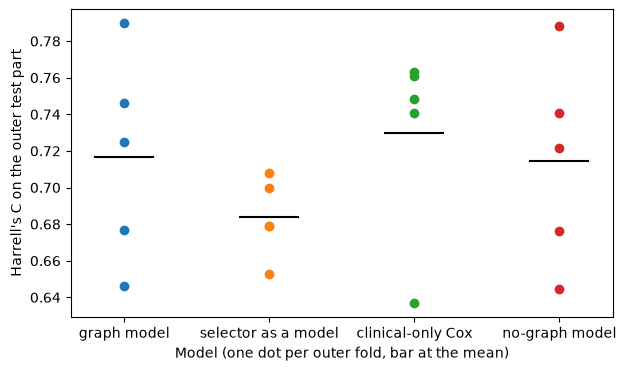

In [27]:
figure, axis = plt.subplots(figsize=(7, 4))
for position, model_name in enumerate(long_table["model"].unique()):
    scores = long_table.loc[long_table["model"] == model_name, "Harrell's C"]
    axis.plot([position] * len(scores), scores, "o", label=model_name)
    axis.plot([position - 0.2, position + 0.2], [scores.mean()] * 2, color="black")
axis.set_xticks(range(long_table["model"].nunique()), long_table["model"].unique())
axis.set_ylabel("Harrell's C on the outer test part")
axis.set_xlabel("Model (one dot per outer fold, bar at the mean)")
plt.show()

## Part 2: the final model

A plain five-fold cross-validation on all patients runs stage A then stage B once more to choose the final settings; the selector refitted on all patients gives the final gene list; the graph model is trained on all patients and frozen. The list need not equal any fold's list, and its size is not fixed in advance.

In [28]:
final_dir = RESULTS / "final_model"
final_file = final_dir / "model.pt"
if COMPUTE and len(fold_records) == OUTER_FOLDS and not final_file.exists():
    final_dir.mkdir(exist_ok=True)
    started = time.time()
    all_inner = folds(table, INNER_FOLDS)
    setting, grid = stage_a(table, all_inner)
    graph_setting, inner_table, few_genes = stage_b(table, all_inner, setting, grid)
    x_all, _ = scaled_expression(table, table)
    final_genes, _ = select_genes(x_all, outcome_of(table), setting, grid)
    c_all, _ = clinical_vectors(table, table)
    model = train_graph_model(patient_graphs(x_all, final_genes, edges), c_all, table,
                              int(graph_setting["hidden size"]), float(graph_setting["dropout"]))
    frozen = {"state": model.state_dict(), "hidden size": int(graph_setting["hidden size"]),
              "dropout": float(graph_setting["dropout"]), "genes": final_genes,
              "l1 ratio": float(setting["l1 ratio"]), "penalty": float(setting["penalty"]),
              "clinical levels": {name: sorted(table[name].unique()) for name in CATEGORIES},
              "data sha256": data_hash, "edges sha256": edge_hash}
    torch.save(frozen, final_file)
    stage_a_record, stage_b_record = chosen_settings(setting, grid, graph_setting, inner_table,
                                                     few_genes)
    final_record = {"stage A": stage_a_record, "stage B": stage_b_record,
                    "genes": len(final_genes), "minutes": round((time.time() - started) / 60, 1),
                    "model sha256": hashlib.sha256(final_file.read_bytes()).hexdigest()}
    (final_dir / "final_record.json").write_text(json.dumps(final_record, indent=1))
    (final_dir / "final_genes.txt").write_text("\n".join(final_genes) + "\n")

In [29]:
if final_file.exists():
    final_record = json.loads((final_dir / "final_record.json").read_text())
    final_genes = (final_dir / "final_genes.txt").read_text().split()
    rows = []
    for record in fold_records:
        fold_genes = set((RESULTS / f"outer_fold_{record['fold']}_genes.txt").read_text().split())
        overlap = len(fold_genes & set(final_genes)) / len(fold_genes | set(final_genes))
        row = {"outer fold": record["fold"], "genes": len(fold_genes),
               "Jaccard overlap with the final list": round(overlap, 2)}
        rows.append(row)
    overlaps = pd.DataFrame(rows).set_index("outer fold")
    assert (overlaps["Jaccard overlap with the final list"] < 1).any(), "no fold list differs"
    final_values = {"L1 ratio": final_record["stage A"]["l1 ratio"],
                    "penalty": round(final_record["stage A"]["penalty"], 4),
                    "hidden size": final_record["stage B"]["hidden size"],
                    "dropout": final_record["stage B"]["dropout"],
                    "final genes": final_record["genes"],
                    "model file sha256": final_record["model sha256"][:16] + "...",
                    "minutes": final_record["minutes"]}
    final_table = pd.Series(final_values, name="final model").to_frame()
    final_table.to_csv(RESULTS / "final_settings.csv")
    overlaps.to_csv(RESULTS / "final_overlaps.csv")
    display(final_table, overlaps)
else:
    display(Markdown("The final model is not yet trained."))

,final model
L1 ratio,0.5
penalty,0.0085
hidden size,64
dropout,0.5
final genes,476
model file sha256,6f7305d11b59ed63...
minutes,25.3


,genes,Jaccard overlap with the final list
outer fold,,
1,300,0.30
2,160,0.18
3,472,0.39
4,436,0.33
5,476,0.34


The METABRIC cell below is switched off until the supervisors confirm the procedure; the frozen model scores the external cohort once. Alignment: METABRIC expression z-scored per gene on METABRIC itself for the final genes, age z-scored on METABRIC, clinical levels mapped as in notebook 1.

In [30]:
if SCORE_METABRIC and final_file.exists():
    frozen = torch.load(final_file, weights_only=False)
    metabric = pd.read_parquet("../data/processed/metabric.parquet")
    x_metabric, _ = scaled_expression(metabric, metabric)
    c_metabric, _ = clinical_vectors(metabric, metabric)
    model = GraphModel(frozen["hidden size"], frozen["dropout"], c_metabric.shape[1])
    model.load_state_dict(frozen["state"])
    risk = log_hazard(model, patient_graphs(x_metabric, frozen["genes"], edges), c_metabric)
    external = {"Harrell's C": float(harrell(metabric, risk)),
                "Uno's C (5 years)": float(uno(table, metabric, risk)), "patients": len(metabric)}
    (RESULTS / "metabric_score.json").write_text(json.dumps(external, indent=1))
    display(pd.Series(external, name="METABRIC").to_frame())
else:
    display(Markdown("METABRIC is not scored in this version; the switch in the settings is set "
                     "to no."))

METABRIC is not scored in this version; the switch in the settings is set to no.

## Summary file and run record

The summary holds every number the meeting pages use. The run record names the git commit, the package versions, the seeds, the input hashes and the minutes per stage.

In [31]:
summary = {"outer folds done": len(fold_records)}
for model_name in results_table["Harrell's C"].columns:
    summary[f"{model_name} mean C"] = round(float(means[model_name]), 3)
    spread = results_table.loc["SD", ("Harrell's C", model_name)]
    summary[f"{model_name} SD C"] = round(float(spread), 3)
    mean_uno = results_table.loc["mean", ("Uno's C (5 years)", model_name)]
    summary[f"{model_name} mean Uno C"] = round(float(mean_uno), 3)
for name, row in paired.iterrows():
    short = "graph minus clinical" if "clinical" in name else "graph minus selector"
    summary[f"{short} mean"] = round(float(row["mean difference"]), 3)
    summary[f"{short} lower"] = round(float(row["lower"]), 3)
    summary[f"{short} upper"] = round(float(row["upper"]), 3)
summary["genes selected, smallest"] = int(stage_a_table["genes selected"].min())
summary["genes selected, largest"] = int(stage_a_table["genes selected"].max())
summary["final model trained"] = "yes" if final_file.exists() else "no"
if final_file.exists():
    summary["final genes"] = final_record["genes"]
pd.Series(summary, name="value").to_csv(RESULTS / "summary.csv")
pd.Series(summary, name="value").to_frame()

,value
outer folds done,5
clinical-only Cox mean C,0.73
clinical-only Cox SD C,0.053
clinical-only Cox mean Uno C,0.706
graph model mean C,0.717
graph model SD C,0.057
graph model mean Uno C,0.711
no-graph model mean C,0.714
no-graph model SD C,0.056
no-graph model mean Uno C,0.705


In [32]:
def git(*arguments):
    """The output of one git command, for the run record."""
    command = ["git", *arguments]
    return subprocess.run(command, capture_output=True, text=True, check=True).stdout.strip()


packages = {}
for name in ["numpy", "pandas", "scikit-learn", "scikit-survival", "torch", "torch_geometric",
             "torchsurv"]:
    packages[name] = version(name)
minutes = {}
for record in fold_records:
    stage_minutes = record["minutes"]
    minutes[f"outer fold {record['fold']}"] = (f"stage A {stage_minutes['stage A']}, "
                                               f"stage B {stage_minutes['stage B']}, "
                                               f"stage C {stage_minutes['stage C']}")
run_record = {"git commit": git("rev-parse", "HEAD"),
              "tracked files changed since that commit":
                  git("status", "--porcelain", "--untracked-files=no").splitlines(),
              "mode": "computed" if COMPUTE else "read the saved results",
              "python": sys.version.split()[0], "packages": packages,
              "seeds": {"folds": FOLD_SEED, "torch": TORCH_SEED},
              "cohort table (sha256)": data_hash, "edge list (sha256)": edge_hash,
              "minutes": minutes}
record_name = "compute_record.json" if COMPUTE else "run_record.json"
(RESULTS / record_name).write_text(json.dumps(run_record, indent=1))
print(json.dumps(run_record, indent=1))

{
 "git commit": "d4f760fffef384b761f67f99f26f3b63fe0d34f8",
 "tracked files changed since that commit": [
  "M notebooks/05_pipeline.ipynb"
 ],
 "mode": "read the saved results",
 "python": "3.12.14",
 "packages": {
  "numpy": "2.5.3",
  "pandas": "3.0.6",
  "scikit-learn": "1.9.1",
  "scikit-survival": "0.28.0",
  "torch": "2.14.0+cpu",
  "torch_geometric": "2.8.0.post1",
  "torchsurv": "0.2.0"
 },
 "seeds": {
  "folds": 0,
  "torch": 0
 },
 "cohort table (sha256)": "5879c2e0d13c56b6404c750a2eb0d2491605ff59d245e5fbd8e8331eb847a780",
 "edge list (sha256)": "e8116725e93b7b20c03b5d83759a48541bf17fd51e179ea95894c382fcf5f79b",
 "minutes": {
  "outer fold 1": "stage A 1.3, stage B 11.8, stage C 0.6",
  "outer fold 2": "stage A 1.1, stage B 7.1, stage C 0.5",
  "outer fold 3": "stage A 1.1, stage B 17.7, stage C 1.8",
  "outer fold 4": "stage A 1.2, stage B 17.1, stage C 0.8",
  "outer fold 5": "stage A 1.1, stage B 17.6, stage C 0.9"
 }
}
